# Foundations: is this strawberry purée?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/01_Foundations/notebooks/TD1_strawberry_student.ipynb)

A supplier claims that a fruit purée is strawberry. We have infrared
measurements from samples recorded as Strawberry or NON-Strawberry. We will
use those measurements to train a small decision tree and a small neural
network to predict the recorded target. This is a classification task.

All code is supplied. Run the cells from top to bottom with their ▶ buttons.
Read the explanation above each cell and inspect its output. To answer a
question, double-click its Your answer text cell and write in words.

Click Open in Colab above to start this notebook. Use the standard CPU runtime.

## 1. Look at the measurements

Each sample is one recorded measurement of a fruit purée. Its infrared
spectrum contains 235 signal values measured at different wavenumbers.
A wavenumber identifies a position along the infrared spectrum.

A feature is a number describing a sample. For now, each measured signal
at a particular wavenumber is one feature: 235 features per sample.
The target is the recorded outcome we want to predict. Its possible
values are called classes. The target is kept separate from the features.

Strawberry is one class. NON-Strawberry includes other fruit purées and
adulterated strawberry mixtures. The file does not identify the particular
adulterant or its amount for each sample.

The first cell loads the tools: `pd` works with tables and `plt` draws plots.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

Read the public data file. Its first row contains sample targets, so
`header=None` keeps that row in the table. The fixed address selects the
same version of the source file throughout the strawberry practicals.

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/zwbben/SpectroscopyData/"
    "4db9b8168fac1185973d1e7888d51f7f33f94857/MIR_Fruit_purees.csv"
)
raw_data = pd.read_csv(DATA_URL, header=None)

Here is the table as it was read. Row 0 gives the sample targets. Column 0
gives the wavenumbers, starting below the word Wavenumbers. Each remaining
column contains one sample's spectrum. The table has 983 sample columns.
Only the first and last parts of this large table are displayed.

In [3]:
raw_data

,0,1,2,3,4,5,6,7,8,9,...,974,975,976,977,978,979,980,981,982,983
0,Wavenumbers,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,...,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry
1,899.327,0.002805507,0.00263738,0.002415868,0.00234529,0.002302508,0.002513791,0.002105496,0.002018384,0.002153632,...,0.002539315,0.002568574,0.002723227,0.002542207,0.00262688,0.002631082,0.002730378,0.002712845,0.002696845,0.002789428
2,903.187,0.002731944,0.002638345,0.002479677,0.002291981,0.00234218,0.002488288,0.002078167,0.0019987,0.002165058,...,0.002507276,0.002568594,0.002714211,0.002538884,0.002629394,0.002650873,0.002838751,0.0027786,0.00290547,0.003039869
3,907.047,0.00266115,0.002651382,0.002510657,0.002248641,0.00234953,0.00247745,0.002077299,0.001944556,0.002191274,...,0.002482726,0.002541337,0.002739762,0.002574314,0.002618641,0.002696092,0.002999267,0.002877433,0.003277223,0.003358926
4,910.907,0.00265707,0.002757381,0.002611341,0.002303143,0.002419224,0.002542069,0.002154436,0.001963826,0.002274862,...,0.002562686,0.002598623,0.002860805,0.002663535,0.002713847,0.002809383,0.003258967,0.003084947,0.003711203,0.003796026
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
231,1787.124,8.70401E-05,-5.50734E-06,6.22218E-05,7.52099E-05,9.87553E-05,5.40501E-05,6.37965E-05,0.000101614,8.11771E-05,...,4.1971E-06,8.43141E-06,8.41589E-06,5.40847E-06,1.21E-05,-1.26769E-06,-7.71062E-07,6.59038E-06,-9.43563E-06,-2.02171E-05
232,1790.984,4.58481E-05,1.84089E-06,3.11324E-05,4.29712E-05,5.37301E-05,3.14769E-05,4.30507E-05,6.35453E-05,5.52157E-05,...,6.96074E-06,1.84257E-05,1.02528E-05,6.93735E-06,1.21853E-05,2.9724E-06,2.04995E-07,6.81436E-06,-5.09051E-06,-5.91353E-06
233,1794.844,1.08289E-05,9.65908E-06,8.81474E-06,2.10302E-05,1.97074E-05,1.60126E-05,2.71518E-05,3.76145E-05,3.25956E-05,...,1.43265E-05,1.41472E-05,1.49764E-05,1.29431E-05,9.70352E-06,7.40502E-06,6.58678E-06,1.21564E-05,-2.41264E-06,-5.06714E-06
234,1798.704,9.39817E-06,5.07603E-06,7.15697E-06,7.53529E-06,1.17139E-05,8.13114E-06,1.19344E-05,1.46512E-05,1.35374E-05,...,1.08665E-05,1.1123E-05,1.0027E-05,9.52043E-06,6.39644E-06,7.76824E-06,5.12522E-06,1.28675E-05,1.04989E-06,-1.83347E-06


Separate the targets from the numbers. Because each source column contains
both words and numbers, the values were initially read as text.
`astype(float)` converts the numerical part to numbers, once.

`iloc` selects rows or columns by their position. `.T` swaps rows and
columns so that each row of `spectra` becomes one sample. The last line
uses the wavenumbers to name its columns.

In [4]:
targets = raw_data.iloc[0, 1:]
numeric_data = raw_data.iloc[1:].astype(float)
spectra = numeric_data.iloc[:, 1:].T
spectra.columns = numeric_data.iloc[:, 0]

Two records have exactly the same measurements but opposite targets.
We leave both out because the file cannot tell us which target is right.
`~` means “not”: keep the rows that are not repeated. This leaves 981
spectra: 350 Strawberry and 631 NON-Strawberry.

In [5]:
repeated = spectra.duplicated(keep=False)
spectra = spectra.loc[~repeated]
targets = targets.loc[~repeated]
print("Samples kept:", len(spectra))
print(targets.value_counts())

Samples kept: 981
0
NON-Strawberry    631
Strawberry        350
Name: count, dtype: int64


The measurements now have one sample per row and one wavenumber per column.
Show the first five rows and six measured wavenumbers. Each entry is that
sample's supplied infrared signal at that wavenumber. The row numbers
identify positions in the source file, not physical specimen IDs.

In [6]:
spectra.iloc[:5, :6]

,899.327,903.187,907.047,910.907,914.767,918.627
1,0.002806,0.002732,0.002661,0.002657,0.002699,0.002762
2,0.002637,0.002638,0.002651,0.002757,0.003000,0.003313
3,0.002416,0.002480,0.002511,0.002611,0.002802,0.003031
4,0.002345,0.002292,0.002249,0.002303,0.002466,0.002642
5,0.002303,0.002342,0.002350,0.002419,0.002561,0.002737


### Draw two example spectra

Select the first recorded example from each class. Each line below joins
its 235 measured signals. These are two individual examples, not class
averages. Similar-looking spectra can still have different targets.
The CSV does not establish absolute physical units for the supplied signal.

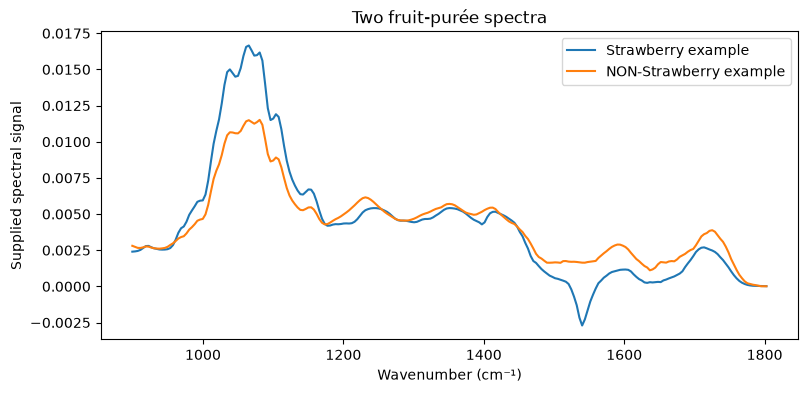

In [7]:
strawberry_id = targets.loc[targets == "Strawberry"].index[0]
other_id = targets.loc[targets == "NON-Strawberry"].index[0]
plt.figure(figsize=(9, 4))
plt.plot(spectra.columns, spectra.loc[strawberry_id], label="Strawberry example")
plt.plot(spectra.columns, spectra.loc[other_id], label="NON-Strawberry example")
plt.xlabel("Wavenumber (cm⁻¹)")
plt.ylabel("Supplied spectral signal")
plt.title("Two fruit-purée spectra")
plt.legend()
plt.show()

## 2. Describe each spectrum with eight numbers

Instead of giving the model all 235 signals, we divide the spectrum into
eight fixed windows and take the average signal in each window. These
eight averages become our new features, B1 to B8. For example, B1 averages
the signal between 899 and 1012 cm⁻¹. It is not a sugar concentration.

Each line below selects one range with `loc` and averages it for every
sample with `mean(axis=1)`. `head()` shows five rows. The original spectra remain available in `spectra`.

`round(4)` displays four digits after the decimal point: for example,
0.123456 becomes 0.1235. The calculations keep the full precision.

In [8]:
features = pd.DataFrame(index=spectra.index)
features["B1"] = spectra.loc[:, 899:1012].mean(axis=1)
features["B2"] = spectra.loc[:, 1012:1125].mean(axis=1)
features["B3"] = spectra.loc[:, 1125:1238].mean(axis=1)
features["B4"] = spectra.loc[:, 1238:1351].mean(axis=1)
features["B5"] = spectra.loc[:, 1351:1464].mean(axis=1)
features["B6"] = spectra.loc[:, 1464:1577].mean(axis=1)
features["B7"] = spectra.loc[:, 1577:1690].mean(axis=1)
features["B8"] = spectra.loc[:, 1690:1803].mean(axis=1)
features.head().round(4)

,B1,B2,B3,B4,B5,B6,B7,B8
1,0.0035,0.0097,0.0052,0.0051,0.0049,0.0019,0.0020,0.0019
2,0.0046,0.0149,0.0052,0.0043,0.0047,0.0006,-0.0003,0.0002
3,0.0041,0.0098,0.0050,0.0048,0.0047,0.0019,0.0022,0.0017
4,0.0037,0.0107,0.0055,0.0052,0.0045,0.0009,0.0015,0.0022
5,0.0038,0.0104,0.0057,0.0053,0.0044,0.0008,0.0012,0.0024


Draw the same two samples again, now using only their eight window means.
Each point represents one window's average. Compare these lines with the
original spectra: broad patterns remain, while individual peaks are lost.
The models below receive these eight values, not the original 235 signals.

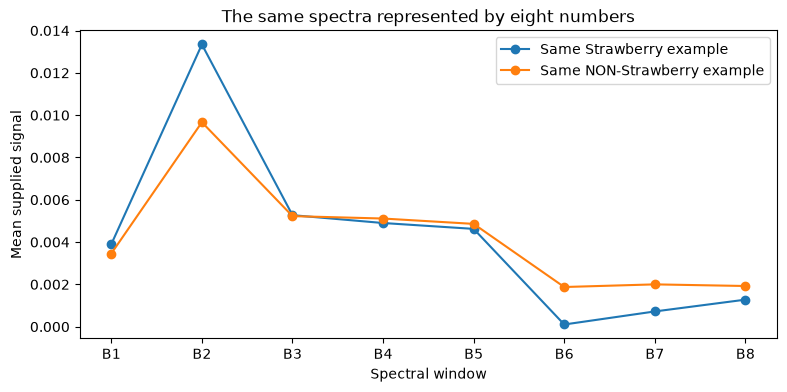

In [9]:
plt.figure(figsize=(9, 4))
plt.plot(features.columns, features.loc[strawberry_id], marker="o", label="Same Strawberry example")
plt.plot(features.columns, features.loc[other_id], marker="o", label="Same NON-Strawberry example")
plt.xlabel("Spectral window")
plt.ylabel("Mean supplied signal")
plt.title("The same spectra represented by eight numbers")
plt.legend()
plt.show()

### Stop and explain 1

What is a sample, and what are the inputs to the models? Explain where
one B1 value comes from and one detail that averaging a window can lose.

Your answer:

Write your answer here in words.

## 3. Keep some samples for testing

Training samples are the examples a model learns from. Test samples are
kept aside to check predictions on records excluded from training.

Keep 80% for training and 20% for testing: 784 and 197 samples. Both models
will use these same groups. `stratify=targets` keeps similar class proportions;
`random_state=42` makes the split repeatable.

In the code, X means features and y means recorded targets. The endings
`_train` and `_test` identify the sample groups.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    features, targets, test_size=0.20, random_state=42, stratify=targets
)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 784
Test samples: 197


### Stop and explain 2

Why should both models be tested on samples they did not learn from?
Why do we give them the same training and test groups?

Your answer:

Write your answer here in words.

## 4. Teach a small decision tree

Imagine sorting the training samples into smaller groups. A tree first
divides them using a rule such as whether B6 is below a chosen value.
Each group can be divided once more using another feature rule. In each
final group, the more common target becomes its prediction. A new sample
follows the same rules to reach one of these final groups.

`fit` chooses the features and cut-off values from the training examples.
We supply the maximum size: `max_depth=2` allows two decisions along a
route. The test samples do not choose these rules.

In [11]:
tree = DecisionTreeClassifier(max_depth=2, random_state=42)
tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

Read the tree from the top. A true condition follows the left branch;
a false condition follows the right. A final box gives the predicted class.
`samples` counts training examples reaching a box; `value` gives their
counts in the order [NON-Strawberry, Strawberry].

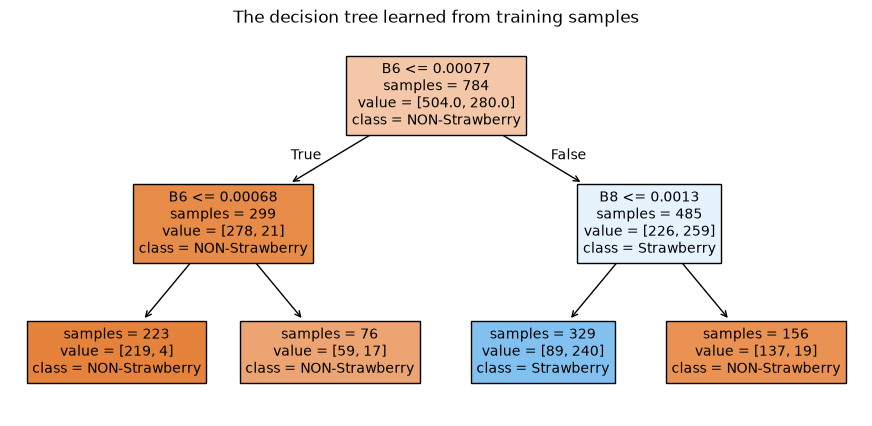

In [12]:
plt.figure(figsize=(11, 5))
plot_tree(tree, feature_names=features.columns,
          class_names=["NON-Strawberry", "Strawberry"],
          filled=True, impurity=False, precision=5, fontsize=10)
plt.title("The decision tree learned from training samples")
plt.show()

### Stop and explain 3

Read the first question in the tree. Which feature does it use, and which
branch does a smaller value follow? Does every final box contain only one class?

Your answer:

Write your answer here in words.

## 5. Test the tree

`predict` applies the learned rules to the test features. Place each
prediction beside its recorded target. These test targets check the model;
they did not teach it.

In [13]:
predictions = tree.predict(X_test)
prediction_table = pd.DataFrame({"Target": y_test, "Prediction": predictions})
prediction_table.head()

,Target,Prediction
553,Strawberry,Strawberry
940,NON-Strawberry,NON-Strawberry
452,Strawberry,Strawberry
76,Strawberry,Strawberry
155,NON-Strawberry,NON-Strawberry


Accuracy is the fraction of predictions matching their recorded targets.
An accuracy of 0.90 means that 90% of the samples were classified correctly.
Compare the tree with a rule that always predicts NON-Strawberry, the most
common training target. `==` checks whether a target matches NON-Strawberry;
`mean()` gives the fraction of matches.

Displayed scores are rounded to three decimal places: for example,
0.87654 is shown as 0.877. This changes the display, not the score used.

In [14]:
tree_accuracy = accuracy_score(y_test, predictions)
baseline_accuracy = (y_test == "NON-Strawberry").mean()
print("Always predict NON-Strawberry:", round(baseline_accuracy, 3))
print("Small decision tree:", round(tree_accuracy, 3))

Always predict NON-Strawberry: 0.645
Small decision tree: 0.883


### Stop and explain 4

Does the tree perform better than always predicting NON-Strawberry?
Quote both accuracies. Why is 100% accuracy not a sensible promise for new samples?

Your answer:

Write your answer here in words.

### Look at the mistakes

This table of counts is a confusion matrix. Rows show recorded targets;
columns show predictions. The diagonal contains correct predictions.

A NON-Strawberry sample predicted Strawberry is a false acceptance.
A Strawberry sample predicted NON-Strawberry is a false rejection.

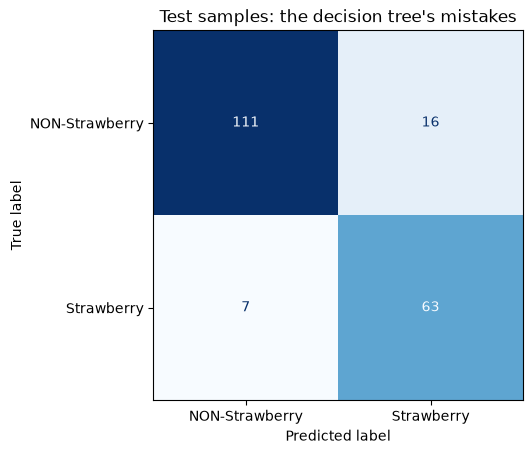

In [15]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=["NON-Strawberry", "Strawberry"],
    cmap="Blues", colorbar=False
)
plt.title("Test samples: the decision tree's mistakes")
plt.show()

### Stop and explain 5

How many false acceptances and false rejections occurred? Give one
practical consequence of each for a laboratory checking incoming products.

Your answer:

Write your answer here in words.

## 6. Teach a small neural network

A neural network combines the input values using weights learned during
training. This one takes B1 to B8, uses one hidden layer of four neurons,
and predicts the same two classes. It does not require us to write the
rules ourselves. Its calculation is less easy to follow than the tree's
short sequence of questions.

First put the eight features on comparable numerical scales. The scaler
learns each feature's average and spread from training samples only.
`fit_transform` learns and applies that rule; `transform` applies the same
rule to the test features. Test samples do not set the scaling rule.

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Create the network and train it. `hidden_layer_sizes=(4,)` means one
hidden layer with four neurons. `solver` selects the training method;
`max_iter` limits the training steps. These settings are supplied and
fixed in advance, just like the tree's depth limit.

In [17]:
network = MLPClassifier(
    hidden_layer_sizes=(4,), solver="lbfgs", max_iter=1000, random_state=42
)
network.fit(X_train_scaled, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(4,)"
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'lbfgs'
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


Make predictions using the scaled test features. The table compares the
models' accuracies on exactly the same 197 test samples. The tree still
uses the original eight values; the network uses their scaled versions.

In [18]:
network_predictions = network.predict(X_test_scaled)
network_accuracy = accuracy_score(y_test, network_predictions)
comparison = pd.DataFrame({
    "Model": ["Decision tree", "Small neural network"],
    "Test accuracy": [tree_accuracy, network_accuracy]
})
comparison.round(3)

,Model,Test accuracy
0,Decision tree,0.883
1,Small neural network,0.914


Read the network's mistakes using the same row and column order as before.
A higher overall accuracy need not mean that both kinds of mistake decrease.

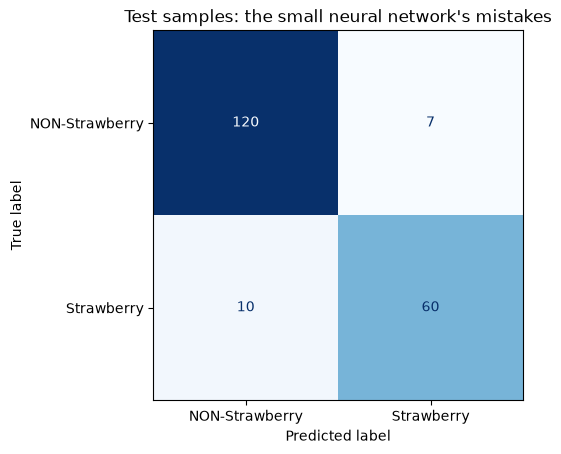

In [19]:
ConfusionMatrixDisplay.from_predictions(
    y_test, network_predictions, labels=["NON-Strawberry", "Strawberry"],
    cmap="Blues", colorbar=False
)
plt.title("Test samples: the small neural network's mistakes")
plt.show()

### Stop and explain 6

Compare the two accuracies and mistake tables. Does the network reduce
both false acceptances and false rejections? Write two or three sentences
explaining why the higher accuracy alone does not settle which model a
laboratory should use.

Your answer:

Write your answer here in words.

## 7. Explain what the models can tell us

Both models learned from eight summaries of measured infrared signals.
Their predictions concern the two classes in this dataset. They cannot
identify an adulterant, measure its amount or prove that a sample is pure.

Keep the settings fixed after viewing test results. In Evaluation, we
introduce a validation group to help choose between models before testing.
The tree models keep these eight features; a CNN uses the full spectra.
All models keep the same test samples. Applications then returns to the
eight features and asks which measurements look unusual.

## Data and reuse

The dataset contains measured infrared spectra of fruit purées. The
original file has 983 spectra; 981 remain after excluding the conflicting
pair. NON-Strawberry includes other fruits and adulterated mixtures.
The file does not give separate adulterant, supplier or replicate IDs.
These exercises cannot establish product purity or identify an adulterant.

- Holland, Kemsley and Wilson (1998), *Use of Fourier transform infrared
  spectroscopy and partial least squares regression for the detection of
  adulteration of strawberry purées*.
  [Original study](https://research-portal.uea.ac.uk/en/publications/use-of-fourier-transform-infrared-spectroscopy-and-partial-least-/).
- Shu, Tang, Zhang and Zheng (2019),
  [dataset deposition](https://doi.org/10.17632/frrv2yd9rg.1), version 1.
  Data licence: [CC BY-NC 3.0](https://creativecommons.org/licenses/by-nc/3.0/).
  The data licence is separate from the course-code licence.

The fixed spectral windows are teaching summaries, not selected chemical
markers. This exercise does not reproduce the original paper's analysis.

[Neural networks and feature scaling in scikit-learn](https://scikit-learn.org/stable/modules/neural_networks_supervised.html).